# 06 - Finishing stage 2, quoting promise dates, and serving it

Three additions, all built after the headline results were fixed:

1. **Stage 2, completed:** a calibrated probability and plain-English reasons for the handover model.
2. **S1 - promise dates:** can the platform quote a shorter promise at the same on-time share?
3. **S3 - an API:** the same scoring and reasons over HTTP, in a container.

Every number is read from generated files (`stage2_results.json`, `stage2_explain_summary.json`,
`eta_results.json`) or computed live from the artifacts.
**Honest status, up front:** the test months have now been looked at three times (stage 1, stage 2, promise
model). Levels and models were chosen on validation each time and disclosed, but this is development
evidence, not a fresh hold-out.

In [1]:
import warnings

warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from ontime.config import load_config, project_path

REP = project_path(load_config()["paths"]["reports_dir"])
rj = lambda n: json.loads((REP / n).read_text("utf-8"))
s2, s2x, eta = rj("stage2_results.json"), rj("stage2_explain_summary.json"), rj("eta_results.json")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Stage 2: probabilities with honest limits
The handover model was selected for *ranking*. To offer probabilities we fit a calibrator on **validation**
scores only (method chosen forward in time: fit on the early part, check on the later part) and report
quality on the **test** months, which never fit anything.

In [2]:
cal = s2["calibration"]
t = cal["test"]
tbl = pd.DataFrame(
    {
        "Brier": [
            t["raw"]["brier"],
            t["calibrated"]["brier"],
            t["stage1_deployed"]["brier"],
            t["constant_at_true_rate_brier"],
        ],
        "Log loss": [
            t["raw"]["log_loss"],
            t["calibrated"]["log_loss"],
            t["stage1_deployed"]["log_loss"],
            np.nan,
        ],
        "ECE": [t["raw"]["ece"], t["calibrated"]["ece"], t["stage1_deployed"]["ece"], np.nan],
    },
    index=[
        "stage 2 raw",
        f"stage 2 calibrated ({cal['method']})",
        "stage 1 (deployed)",
        "always predict the true rate",
    ],
)
display(tbl)
fwd = cal["forward_selection_scores_validation"]
Markdown(f"""
**Inference.** Raw LightGBM scores are badly miscalibrated (ECE **{t["raw"]["ece"]:.2f}**, Brier
**{t["raw"]["brier"]:.3f}**): its probabilities are fine for ranking, not for reading as percentages.
The {cal["method"]} calibrator (chosen because it had the lowest forward-in-time Brier,
{min(v["brier"] for v in fwd.values()):.4f}) brings Brier to **{t["calibrated"]["brier"]:.4f}**, which beats
always predicting the base rate ({t["constant_at_true_rate_brier"]:.4f}). Stage 1's Brier
({t["stage1_deployed"]["brier"]:.4f}) is no better than that constant: its value is in ranking, not in
probabilities. The stage-2 ECE ({t["calibrated"]["ece"]:.3f}) is *not* better than stage 1's
({t["stage1_deployed"]["ece"]:.3f}): the late rate moved between periods, which is why the app and API
report a **relative risk** next to the probability.
""")

,Brier,Log loss,ECE
stage 2 raw,0.1390,0.4408,0.2898
stage 2 calibrated (isotonic),0.0348,0.1454,0.0219
stage 1 (deployed),0.0435,0.1773,0.0150
always predict the true rate,0.0434,NaN,NaN



**Inference.** Raw LightGBM scores are badly miscalibrated (ECE **0.29**, Brier
**0.139**): its probabilities are fine for ranking, not for reading as percentages.
The isotonic calibrator (chosen because it had the lowest forward-in-time Brier,
0.0349) brings Brier to **0.0348**, which beats
always predicting the base rate (0.0434). Stage 1's Brier
(0.0435) is no better than that constant: its value is in ranking, not in
probabilities. The stage-2 ECE (0.022) is *not* better than stage 1's
(0.015): the late rate moved between periods, which is why the app and API
report a **relative risk** next to the probability.


## 2. Stage 2 reasons
Same recipe as stage 1: the model's exact log-odds contributions are summed into reason *groups*, and the
largest ones become sentences. Four new groups cover what only exists at handover.

In [3]:
g = pd.Series(s2x["mean_abs_group_contribution"]).sort_values(ascending=False)
new = ["handover_timing", "time_left", "seller_handover_history", "destination_backlog"]
out = g.to_frame("mean |contribution| (log-odds)")
out["new at handover"] = out.index.isin(new)
display(out.head(10))
rc = pd.read_parquet(REP / "stage2_reason_codes.parquet")
Markdown(f"""
**Inference.** {s2x["orders_with_a_stage2_reason"]:.0%} of test orders have at least one handover-only reason among
their top risk factors. The explanations are exact: contributions plus the intercept reproduce the model
output to **{s2x["max_additive_identity_error"]:.0e}**, and the code refuses to run if they do not.
""")

,mean |contribution| (log-odds),new at handover
route_history,0.4541,False
time_left,0.3459,True
destination_backlog,0.3297,True
distance,0.2712,False
handover_timing,0.2206,True
approval_timing,0.1913,False
calendar_peak,0.1827,False
promise_window,0.1506,False
seller_record,0.1135,False
network_delays,0.1031,False



**Inference.** 62% of test orders have at least one handover-only reason among
their top risk factors. The explanations are exact: contributions plus the intercept reproduce the model
output to **2e-14**, and the code refuses to run if they do not.


In [4]:
r = rc.iloc[1234]
print("Order", r["order_id"][:8], "...")
for sentence in r["risk_factors"]:
    print("  +", sentence)
for sentence in r["protective_factors"]:
    print("  -", sentence)

Order 48761cfd ...
  + Seller-to-customer distance is 860 km (adds risk)
  + On this seller-state to customer-state route, about 7% of earlier orders arrived late (adds risk)
  + 13.3 days remain before the promised date at handover (adds risk)
  - 6% of recent shipments to this state are still in transit (reduces risk)
  - Order approved on a Thursday in August at 16:00, 16 h after purchase (reduces risk)


## 3. S1 - promise dates with a quantile model
**Idea.** A late-delivery classifier answers "will it miss the promise?". The platform controls the promise,
so ask the inverse: *what promise would this order meet with probability alpha?* That is a quantile of
delivery time. LightGBM supports it directly (pinball loss).

**Definitions (matched to the dataset's own):** `Y` = delivery date minus approval date in whole days;
lateness is `Y` greater than the promised days. The code checks this reproduces `is_late` before doing
anything else.

In [5]:
print(
    "orders where the integer-day rule disagrees with is_late:", eta["lateness_definition_mismatch"]
)
print({k: f"{v:,}" for k, v in eta["orders"].items()})

orders where the integer-day rule disagrees with is_late: 0.0
{'train': '50,603', 'val_tune': '10,057', 'val_calib': '10,184', 'test': '24,093'}


### The frontier
Each model level is a point: average promise length vs share of orders delivered in time. Olist's own
promise is one point; "Olist plus a constant number of days" is the obvious baseline.

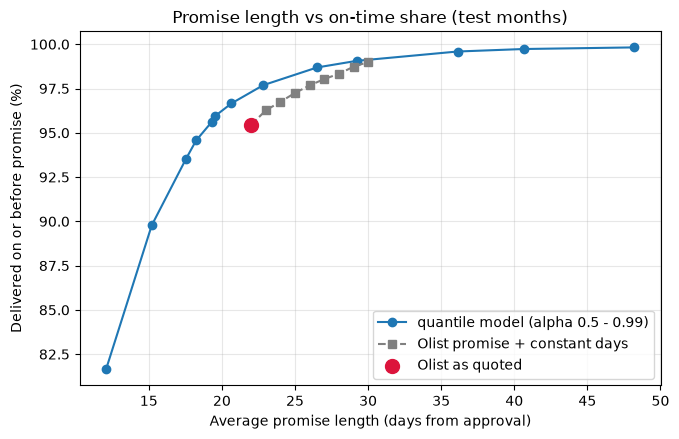

In [6]:
te = eta["test"]
f, sh, o = pd.DataFrame(te["frontier"]), pd.DataFrame(te["shift_baseline"]), te["olist"]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(
    f["mean_promise_days"], f["coverage"] * 100, "o-", label="quantile model (alpha 0.5 - 0.99)"
)
ax.plot(
    sh["mean_promise_days"],
    sh["coverage"] * 100,
    "s--",
    color="grey",
    label="Olist promise + constant days",
)
ax.scatter(
    [o["mean_promise_days"]],
    [o["coverage"] * 100],
    s=100,
    color="crimson",
    zorder=5,
    label="Olist as quoted",
)
ax.set_xlabel("Average promise length (days from approval)")
ax.set_ylabel("Delivered on or before promise (%)")
ax.set_title("Promise length vs on-time share (test months)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [7]:
rows = []
for name, r in te["chosen"].items():
    d = r["vs_olist"]
    rows.append(
        {
            "operating point": name,
            "alpha": r["alpha"],
            "avg promise (d)": r["test_mean_promise_days"],
            "on time": r["test_coverage"],
            "length diff vs Olist": d["length_diff"],
            "CI low": d["length_diff_ci"][0],
            "CI high": d["length_diff_ci"][1],
            "on-time diff (pp)": d["coverage_diff"] * 100,
        }
    )
display(pd.DataFrame(rows).set_index("operating point"))
m = te["chosen"]["match_olist"]
v = m["vs_olist"]
ip = te["interpolated_same_level"]
Markdown(f"""
**Inference.** Choosing the level on validation so that the on-time share matches Olist's
({eta["validation"]["olist"]["coverage"]:.1%}) selects alpha **{m["alpha"]}**. On the test months that gives a
promise **{abs(v["length_diff"]):.1f} days {"shorter" if v["length_diff"] < 0 else "longer"}** than Olist's
on average (95% CI {v["length_diff_ci"][0]:+.1f} to {v["length_diff_ci"][1]:+.1f}) while *more* orders arrive on time
({m["test_coverage"]:.1%} vs {o["coverage"]:.1%}). Read directly off the frontier, Olist's own on-time share
would need about **{ip["length_at_olist_test_coverage"]:.1f}** days instead of **{o["mean_promise_days"]:.1f}**.
""")

,alpha,avg promise (d),on time,length diff vs Olist,CI low,CI high,on-time diff (pp)
operating point,,,,,,,
match_olist,0.8800,20.6497,0.9666,-1.3539,-1.4354,-1.2725,1.2078
cov_0.95,0.9300,26.5060,0.9869,4.5023,4.4036,4.5973,3.2375
cov_0.97,0.9700,36.1164,0.9959,14.1128,14.0079,14.2242,4.1381



**Inference.** Choosing the level on validation so that the on-time share matches Olist's
(92.4%) selects alpha **0.88**. On the test months that gives a
promise **1.4 days shorter** than Olist's
on average (95% CI -1.4 to -1.3) while *more* orders arrive on time
(96.7% vs 95.5%). Read directly off the frontier, Olist's own on-time share
would need about **19.1** days instead of **22.0**.


### Reading it critically
- The points at high alpha (0.95+) are *not* where the value is: the far tail of delivery time is hard to
  predict, so length grows quickly for small gains in safety.
- The constant-shift baseline is competitive when one only wants a safer promise; the model's edge is
  mostly in the *shorter at equal safety* direction.
- A shorter promise is only valuable if customers respond to it; this dataset cannot tell us.
- Third look at the test months, so this is development evidence.

In [8]:
val = eta["validation"]["grid"]
g = pd.DataFrame(val).T[["coverage", "mean_promise_days", "best_iteration"]]
display(g)
Markdown(f"""
**Inference.** Early stopping halts the highest levels after only **{int(g["best_iteration"].iloc[-1])}** boosting
rounds (vs **{int(g["best_iteration"].max())}** at alpha 0.5): tail quantiles stop improving on the
early-stopping slice almost immediately, plausibly because few late examples exist and the validation
months differ from training. Read levels above 0.97 with suspicion; none is offered as an operating point.
""")

,coverage,mean_promise_days,best_iteration
0.5,0.7020,12.7379,290.0000
0.7,0.8238,16.3179,156.0000
0.8,0.8764,18.7797,121.0000
0.82,0.8936,19.6904,150.0000
0.84,0.9103,21.2651,195.0000
0.86,0.9187,21.6409,208.0000
0.88,0.9327,23.4410,125.0000
0.9,0.9434,25.4225,150.0000
0.93,0.9593,29.1842,61.0000
0.95,0.9688,32.0765,75.0000



**Inference.** Early stopping halts the highest levels after only **17** boosting
rounds (vs **290** at alpha 0.5): tail quantiles stop improving on the
early-stopping slice almost immediately, plausibly because few late examples exist and the validation
months differ from training. Read levels above 0.97 with suspicion; none is offered as an operating point.


## 4. S3 - the API
`src/ontime/api/app.py` is a thin FastAPI wrapper over the same `RiskService`, stage-2 and promise
artifacts the app uses. Validation errors come back as HTTP 422 with the exact missing or non-numeric
fields. Below we call it in-process with FastAPI's test client (the Docker image serves the identical app).

In [9]:
from fastapi.testclient import TestClient
from ontime.api.app import app

c = TestClient(app)
print(c.get("/health").json())
feats = pd.read_parquet(project_path(load_config()["paths"]["features_parquet"]))
oid = feats[feats["split"] == "test"]["order_id"].iloc[10]
r1 = c.get(f"/demo/orders/{oid}").json()
r2 = c.get(f"/demo/orders/{oid}", params={"stage": 2}).json()
for tag, r in (("stage 1 (approval)", r1), ("stage 2 (handover)", r2)):
    print(
        f"{tag}: probability {r['probability']:.3f}, relative risk {r['risk_ratio']:.2f}, calibration {r['calibration']}"
    )
    for sentence in r["risk_factors"][:2]:
        print("   +", sentence)

{'status': 'ok', 'version': '1.0', 'artifacts': {'stage1': True, 'stage2': True, 'promise': True}}


stage 1 (approval): probability 0.112, relative risk 1.98, calibration none
   + On this seller-state to customer-state route, about 13% of earlier orders arrived late (adds risk)
   + Seller's record: an estimated 6% late over the last 90 days, 2 completed orders so far (adds risk)
stage 2 (handover): probability 0.029, relative risk 0.51, calibration isotonic
   + On this seller-state to customer-state route, about 13% of earlier orders arrived late (adds risk)
   + 23% of recent shipments to this state are still in transit (adds risk)


In [10]:
bad = c.post("/score", json={"features": {"distance_km": 12}})
print(bad.status_code, bad.json()["detail"][:120], "...")

422 missing features: ['log_distance_km', 'same_state', 'customer_region', 'seller_region', 'geo_imputed', 'n_distinct_selle ...


**What to remember.** The API returns the probability *and* a relative risk, because probabilities drift
with the base rate; stage 2 and the promise model are second and third looks at the same test months;
and the container was verified to return the same score for the same order as the local run.